# 04 · Experiments B and C — power and robustness (RQ1, RQ2)

**Experiment B (power).** How much signal does each probe need before it reacts, and how does that depend on sample size and on the *type* of signal?

**Experiment C (robustness).** At a fixed, moderate signal strength, how do irrelevant features and class imbalance change each probe's power?

**Hypotheses tested here**

* **H1c.** At small n, model-based probes have the highest power.
* **H2a.** Per-feature probes (S1, S2, G1) have power close to α when the signal is interaction-only.
* **H2b.** Distance-based probes (S3, S4, G2, G3) lose power faster than model-based probes as irrelevant features are added.
* **H2c.** Under 10:90 imbalance, AUC-based model probes remain calibrated and useful.

**Monte Carlo null.** The data-generating process is known, so for every setting (n, number of irrelevant features, positive rate) the null distribution of each probe is simulated once from *reference* null datasets. Every replicate in that setting is then tested against this shared null. Additional *hold-out* null datasets, not used to build the reference, measure each probe's false-positive rate under this procedure.

| Experiment | Factors | Signal replicates | Null reference / hold-out |
|---|---|---|---|
| B | type ∈ {linear, nonlinear, interaction} × Bayes AUC ∈ {0.55, 0.60, 0.70, 0.85} × n ∈ {200, 1000, 5000}; 20 irrelevant features; balanced | 25 (15 at n = 5000) | 120 / 80 (80 / 60 at n = 5000) |
| C | type × irrelevant features ∈ {0, 20, 200} × positive rate ∈ {0.5, 0.1}; n = 1000; Bayes AUC = 0.70 | 25 | 80 / – |

Each setting is cached in `results/expBC/` so that an interrupted run resumes where it stopped.

In [1]:
import json
import pickle
import zlib
def load_library_source(path="01_probe_library.ipynb"):
    """Concatenate the code cells of the library notebook so they can be executed here."""
    nb = json.load(open(path, encoding="utf-8"))
    return "\n\n".join("".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code")

_LIBRARY_IMPORT = True
exec(compile(load_library_source(), "probe_library", "exec"))
import matplotlib.pyplot as plt

CACHE_DIR = os.path.join(RESULTS_DIR, "expBC")
os.makedirs(CACHE_DIR, exist_ok=True)
TYPES = ["linear", "nonlinear", "interaction"]
STRENGTHS = [0.55, 0.60, 0.70, 0.85]

## 1. Generator calibration

For each signal type, strength and class balance the scale $s$ and intercept $b$ are solved numerically so that the population Bayes AUC and positive rate hit their targets.

In [2]:
cal_rows = []
for kind in TYPES:
    for auc in STRENGTHS:
        for pr in (0.5, 0.1):
            c = calibrate_generator(kind, auc, pr)
            cal_rows.append({"type": kind, "target_auc": auc, "pos_rate": pr, **c})
calibration = pd.DataFrame(cal_rows)
calibration.to_csv(os.path.join(RESULTS_DIR, "generator_calibration.csv"), index=False)
calibration.round(4)

,type,target_auc,pos_rate,s,b,bayes_auc
0,linear,0.55,0.5,0.1782,-0.0006,0.55
1,linear,0.55,0.1,0.1777,-2.2104,0.55
2,linear,0.60,0.5,0.3636,-0.0012,0.60
3,linear,0.60,0.1,0.3599,-2.2498,0.60
4,linear,0.70,0.5,0.7912,-0.0024,0.70
5,linear,0.70,0.1,0.7609,-2.4204,0.70
6,linear,0.85,0.5,1.8600,-0.0053,0.85
7,linear,0.85,0.1,1.6593,-3.1019,0.85
8,nonlinear,0.55,0.5,0.1883,0.0009,0.55
9,nonlinear,0.55,0.1,0.1791,-2.2103,0.55


## 2. Simulation engine

In [3]:
def obs_job(kind, n, auc, n_noise, pos_rate, seed, role):
    """Generate one dataset and compute every probe's observed statistic (no permutations)."""
    d = make_synthetic(kind, n, auc, n_noise=n_noise, pos_rate=pos_rate, seed=seed)
    o = observed_statistics(d, seed=seed)
    row = {"type": kind, "n": n, "target_auc": auc if kind != "null" else 0.5, "bayes_auc": d.meta["bayes_auc"],
           "n_noise": n_noise, "pos_rate": pos_rate, "seed": seed, "role": role}
    for name, (val, sec) in o.items():
        row[name] = val
        row[name + "_sec"] = sec
    return row


def run_setting(tag, n, n_noise, pos_rate, n_ref, n_hold, signal_specs, reps):
    """Compute (or load) all datasets of one (n, n_noise, pos_rate) setting."""
    path = os.path.join(CACHE_DIR, f"{tag}.pkl")
    if os.path.exists(path):
        return pd.read_pickle(path)
    base = zlib.crc32(f"{n}|{n_noise}|{pos_rate}".encode()) % 10_000_000   # deterministic seed base
    jobs = [("null", n, 0.5, n_noise, pos_rate, base + i, "null_ref") for i in range(n_ref)]
    jobs += [("null", n, 0.5, n_noise, pos_rate, base + 50_000 + i, "null_holdout") for i in range(n_hold)]
    for kind, auc in signal_specs:
        jobs += [(kind, n, auc, n_noise, pos_rate, base + 100_000 + 1000 * STRENGTHS.index(auc)
                  + 10_000 * TYPES.index(kind) + r, "signal") for r in range(reps)]
    t0 = time.time()
    rows = Parallel(n_jobs=2)(delayed(obs_job)(*j) for j in jobs)
    df = pd.DataFrame(rows)
    df["setting"] = tag
    df.to_pickle(path)
    print(f"{tag}: {len(df)} datasets in {(time.time()-t0)/60:.1f} min")
    return df

## 3. Run Experiment B

In [4]:
B_SETTINGS = {200: (120, 80, 25), 1000: (120, 80, 25), 5000: (80, 60, 15)}
frames = []
for n, (n_ref, n_hold, reps) in B_SETTINGS.items():
    specs = [(k, a) for k in TYPES for a in STRENGTHS]
    frames.append(run_setting(f"B_n{n}_p20_r50", n, 20, 0.5, n_ref, n_hold, specs, reps))
expB_raw = pd.concat(frames, ignore_index=True)
print(expB_raw.groupby(["n", "role"]).size())

B_n200_p20_r50: 500 datasets in 4.3 min
B_n1000_p20_r50: 500 datasets in 13.1 min
B_n5000_p20_r50: 320 datasets in 51.7 min
n     role        
200   null_holdout     80
      null_ref        120
      signal          300
1000  null_holdout     80
      null_ref        120
      signal          300
5000  null_holdout     60
      null_ref         80
      signal          180
dtype: int64


## 4. Run Experiment C

The setting (n = 1000, 20 irrelevant features, balanced) is shared with Experiment B, whose datasets are reused.

In [5]:
frames = []
for n_noise in (0, 20, 200):
    for pr in (0.5, 0.1):
        if n_noise == 20 and pr == 0.5:
            sub = expB_raw[(expB_raw.n == 1000) & ((expB_raw.role != "signal") | (expB_raw.target_auc == 0.70))].copy()
            sub["setting"] = "C_shared_with_B"
            frames.append(sub)
            continue
        specs = [(k, 0.70) for k in TYPES]
        frames.append(run_setting(f"C_n1000_p{n_noise}_r{int(pr*100)}", 1000, n_noise, pr, 80, 0, specs, 25))
expC_raw = pd.concat(frames, ignore_index=True)
print(expC_raw.groupby(["n_noise", "pos_rate", "role"]).size())

C_n1000_p0_r50: 155 datasets in 2.5 min
C_n1000_p0_r10: 155 datasets in 2.6 min
C_n1000_p20_r10: 155 datasets in 4.1 min
C_n1000_p200_r50: 155 datasets in 17.1 min
C_n1000_p200_r10: 155 datasets in 17.9 min
n_noise  pos_rate  role        
0        0.1       null_ref         80
                   signal           75
         0.5       null_ref         80
                   signal           75
20       0.1       null_ref         80
                   signal           75
         0.5       null_holdout     80
                   null_ref        120
                   signal           75
200      0.1       null_ref         80
                   signal           75
         0.5       null_ref         80
                   signal           75
dtype: int64


## 5. Monte Carlo p-values

For each setting the reference null rows give, per probe, the null distribution of the statistic. Per-feature probes are handled as in the library: S1 compares each feature's MI with the pooled null MI values of all reference features; S2 uses its analytic p-values. Both are aggregated with Simes.

In [6]:
SCALAR = [p for p in PROBE_ORDER if p not in ("S1_MI", "S2_ANOVA_Chi2")]

def mc_pvalues(raw):
    """Add a p-value column per probe to every non-reference row, using its own setting's reference."""
    out = []
    for (n, nn, pr), g in raw.groupby(["n", "n_noise", "pos_rate"]):
        ref = g[g.role == "null_ref"]
        test = g[g.role != "null_ref"].copy()
        for probe in SCALAR:
            null = ref[probe].to_numpy(float)
            test["p_" + probe] = [mc_pvalue(t, null) for t in test[probe].to_numpy(float)]
        null_mi = np.concatenate(ref["S1_MI"].to_list())
        test["p_S1_MI"] = [simes([mc_pvalue(v, null_mi) for v in vec]) for vec in test["S1_MI"]]
        test["p_S2_ANOVA_Chi2"] = [simes(vec) for vec in test["S2_ANOVA_Chi2"]]
        out.append(test)
    return pd.concat(out, ignore_index=True)

expB = mc_pvalues(expB_raw)
expC = mc_pvalues(expC_raw)

def long_format(df):
    keep = ["type", "n", "target_auc", "bayes_auc", "n_noise", "pos_rate", "seed", "role"]
    long = df.melt(id_vars=keep, value_vars=["p_" + p for p in PROBE_ORDER], var_name="probe", value_name="p")
    long["probe"] = long.probe.str[2:]
    long["reject"] = long.p <= ALPHA
    return long

expB_long, expC_long = long_format(expB), long_format(expC)
expB_long.to_csv(os.path.join(RESULTS_DIR, "expB_pvalues.csv"), index=False)
expC_long.to_csv(os.path.join(RESULTS_DIR, "expC_pvalues.csv"), index=False)

## 6. False-positive rate of the Monte Carlo procedure (hold-out null data)

In [7]:
hold = expB_long[expB_long.role == "null_holdout"]
fpr_hold = hold.groupby(["probe", "n"]).reject.agg(["mean", "size"]).reset_index().rename(
    columns={"mean": "FPR", "size": "replicates"})
fpr_hold["probe"] = pd.Categorical(fpr_hold.probe, PROBE_ORDER, ordered=True)
fpr_hold = fpr_hold.sort_values(["probe", "n"])
fpr_hold.to_csv(os.path.join(RESULTS_DIR, "expB_fpr_holdout.csv"), index=False)
fpr_hold.pivot(index="probe", columns="n", values="FPR").round(3)

n,200,1000,5000
probe,,,
S1_MI,0.025,0.025,0.100
S2_ANOVA_Chi2,0.050,0.062,0.050
S3_dCor,0.050,0.062,0.033
S4_HSIC,0.050,0.075,0.033
G1_F1,0.050,0.038,0.050
G2_N1,0.025,0.112,0.050
G3_N3,0.012,0.062,0.150
M1_Tree,0.050,0.025,0.083
M2_LogReg,0.050,0.050,0.067


## 7. Power (Experiment B)

In [8]:
sig = expB_long[expB_long.role == "signal"]
powerB = sig.groupby(["probe", "type", "n", "target_auc"]).reject.mean().reset_index().rename(columns={"reject": "power"})
powerB.to_csv(os.path.join(RESULTS_DIR, "expB_power.csv"), index=False)
powerB.pivot_table(index=["type", "n"], columns="probe", values="power", aggfunc="mean")[PROBE_ORDER].round(2)

probe             S1_MI  S2_ANOVA_Chi2  S3_dCor  ...  M2_LogReg  M3_Forest  M4_HGB
type        n                                    ...                              
interaction 200    0.03           0.04     0.00  ...       0.01       0.07    0.15
            1000   0.05           0.02     0.13  ...       0.03       0.34    0.48
            5000   0.00           0.05     0.35  ...       0.07       0.68    0.83
linear      200    0.10           0.52     0.52  ...       0.49       0.35    0.41
            1000   0.23           0.74     0.83  ...       0.74       0.70    0.67
            5000   0.45           0.97     0.98  ...       0.98       0.95    0.92
nonlinear   200    0.11           0.04     0.04  ...       0.02       0.32    0.31
            1000   0.23           0.05     0.38  ...       0.04       0.61    0.55
            5000   0.47           0.00     0.63  ...       0.03       0.92    0.88

[9 rows x 11 columns]

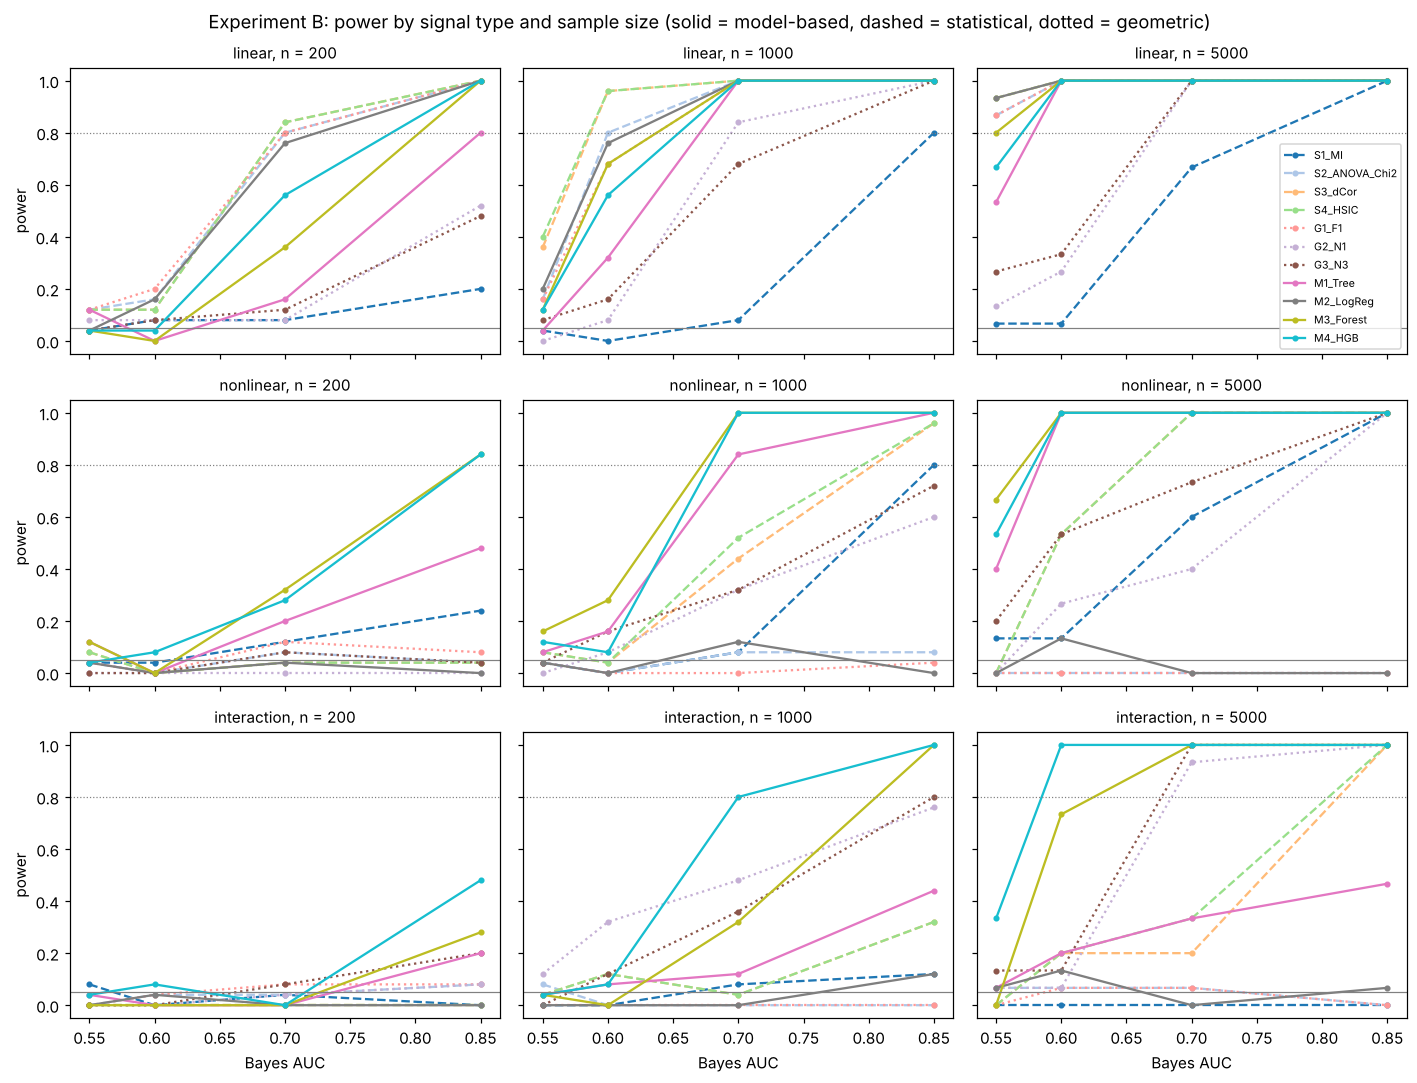

In [9]:
colors = plt.cm.tab20(np.linspace(0, 1, 12))
fig, axes = plt.subplots(3, 3, figsize=(13, 10), sharex=True, sharey=True)
for i, kind in enumerate(TYPES):
    for j, n in enumerate((200, 1000, 5000)):
        ax = axes[i, j]
        for k, probe in enumerate(PROBE_ORDER):
            g = powerB[(powerB.type == kind) & (powerB.n == n) & (powerB.probe == probe)]
            ls = "-" if FAMILY[probe] == "model-based" else ("--" if FAMILY[probe] == "statistical" else ":")
            ax.plot(g.target_auc, g.power, ls, marker="o", ms=3, color=colors[k], label=probe)
        ax.axhline(ALPHA, color="grey", lw=0.8)
        ax.axhline(0.8, color="grey", lw=0.8, ls=":")
        ax.set_title(f"{kind}, n = {n}", fontsize=10)
        if j == 0:
            ax.set_ylabel("power")
        if i == 2:
            ax.set_xlabel("Bayes AUC")
axes[0, 2].legend(fontsize=7, loc="lower right")
plt.suptitle("Experiment B: power by signal type and sample size (solid = model-based, dashed = statistical, dotted = geometric)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "expB_power_curves.png"), dpi=200, bbox_inches="tight")
plt.show()

### Minimum detectable effect (MDE)

The MDE is the smallest Bayes AUC at which a probe reaches 80 % power, found by linear interpolation of the power curve between the tested strengths. "> 0.85" means the probe never reached 80 % power in the tested range.

In [10]:
def mde(g, target=0.8):
    g = g.sort_values("target_auc")
    x, y = g.target_auc.to_numpy(), g.power.to_numpy()
    if y[0] >= target:
        return f"≤ {x[0]:.2f}"
    for k in range(1, len(x)):
        if y[k] >= target:
            return f"{x[k-1] + (target - y[k-1]) * (x[k] - x[k-1]) / (y[k] - y[k-1]):.3f}"
    return f"> {x[-1]:.2f}"

mde_tab = powerB.groupby(["type", "n", "probe"]).apply(mde, include_groups=False).rename("MDE").reset_index()
mde_wide = mde_tab.pivot_table(index="probe", columns=["type", "n"], values="MDE", aggfunc="first").loc[PROBE_ORDER]
mde_wide.to_csv(os.path.join(RESULTS_DIR, "expB_mde.csv"))
mde_wide

type          interaction                  ... nonlinear                
n                    200     1000    5000  ...      200     1000    5000
probe                                      ...                          
S1_MI              > 0.85  > 0.85  > 0.85  ...    > 0.85   0.850   0.775
S2_ANOVA_Chi2      > 0.85  > 0.85  > 0.85  ...    > 0.85  > 0.85  > 0.85
S3_dCor            > 0.85  > 0.85   0.812  ...    > 0.85   0.804   0.657
S4_HSIC            > 0.85  > 0.85   0.805  ...    > 0.85   0.795   0.657
G1_F1              > 0.85  > 0.85  > 0.85  ...    > 0.85  > 0.85  > 0.85
G2_N1              > 0.85  > 0.85   0.685  ...    > 0.85  > 0.85   0.800
G3_N3              > 0.85   0.850   0.677  ...    > 0.85  > 0.85   0.738
M1_Tree            > 0.85  > 0.85  > 0.85  ...    > 0.85   0.694   0.583
M2_LogReg          > 0.85  > 0.85  > 0.85  ...    > 0.85  > 0.85  > 0.85
M3_Forest          > 0.85   0.806   0.625  ...     0.838   0.672   0.570
M4_HGB             > 0.85   0.700   0.585  ...     0.839   0.678   0.579

[11 rows x 9 columns]

## 8. Robustness (Experiment C)

In [11]:
sigC = expC_long[expC_long.role == "signal"]
powerC = sigC.groupby(["probe", "type", "n_noise", "pos_rate"]).reject.mean().reset_index().rename(columns={"reject": "power"})
powerC.to_csv(os.path.join(RESULTS_DIR, "expC_power.csv"), index=False)
powerC.pivot_table(index=["type", "pos_rate"], columns=["probe", "n_noise"], values="power")[PROBE_ORDER].round(2)

probe                S1_MI             S2_ANOVA_Chi2  ... M3_Forest M4_HGB            
n_noise                0     20    200           0    ...       200    0     20    200
type        pos_rate                                  ...                             
interaction 0.1       0.16  0.04  0.08          0.08  ...      0.20   0.72  0.36  0.12
            0.5       0.08  0.08  0.00          0.08  ...      0.08   1.00  0.80  0.00
linear      0.1       0.44  0.12  0.04          1.00  ...      0.32   0.88  0.80  0.44
            0.5       0.36  0.08  0.08          1.00  ...      1.00   1.00  1.00  1.00
nonlinear   0.1       0.40  0.12  0.08          0.24  ...      0.80   0.68  0.60  0.20
            0.5       0.60  0.08  0.04          0.00  ...      0.72   1.00  1.00  0.96

[6 rows x 33 columns]

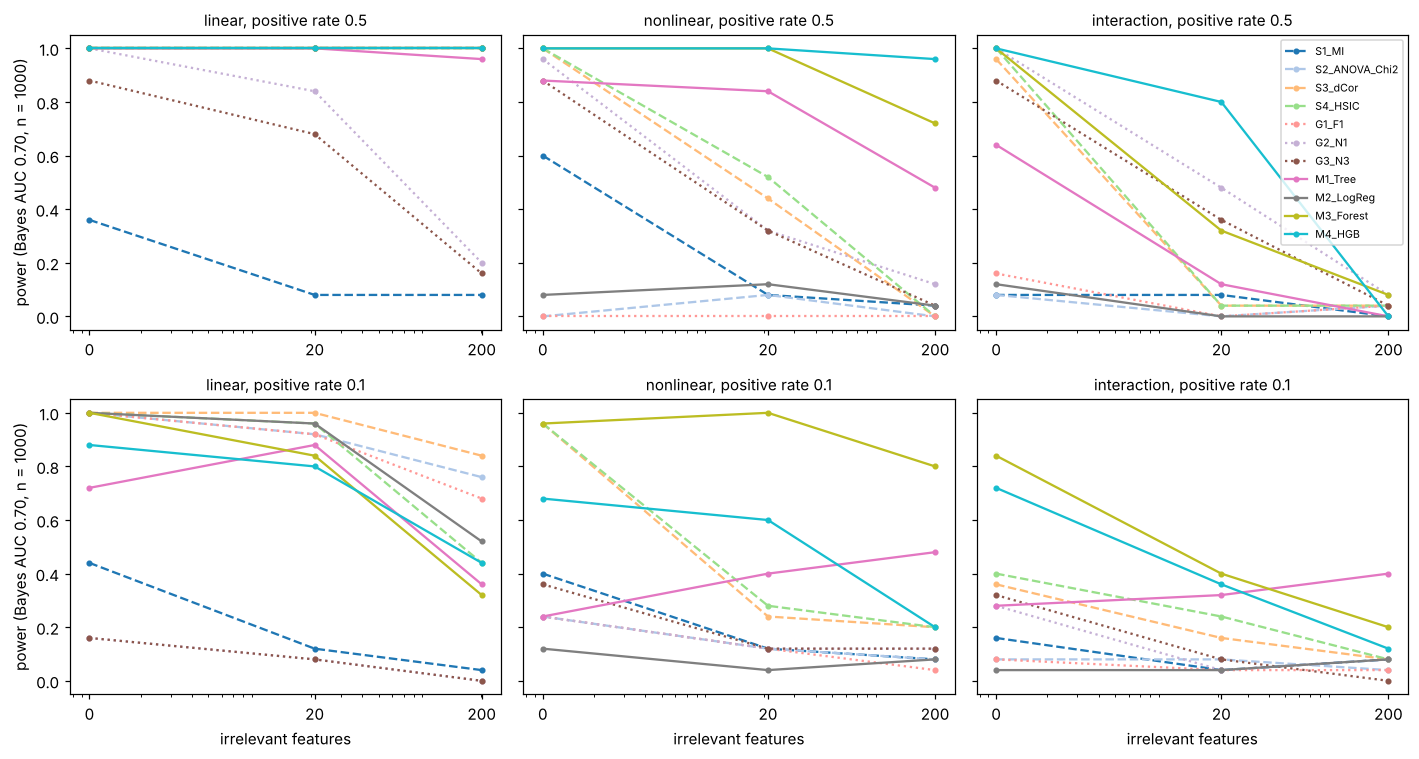

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for i, pr in enumerate((0.5, 0.1)):
    for j, kind in enumerate(TYPES):
        ax = axes[i, j]
        for k, probe in enumerate(PROBE_ORDER):
            g = powerC[(powerC.type == kind) & (powerC.pos_rate == pr) & (powerC.probe == probe)].sort_values("n_noise")
            ls = "-" if FAMILY[probe] == "model-based" else ("--" if FAMILY[probe] == "statistical" else ":")
            ax.plot(g.n_noise + 1, g.power, ls, marker="o", ms=3, color=colors[k], label=probe)
        ax.set_xscale("log")
        ax.set_xticks([1, 21, 201])
        ax.set_xticklabels(["0", "20", "200"])
        ax.set_title(f"{kind}, positive rate {pr}", fontsize=10)
        if i == 1:
            ax.set_xlabel("irrelevant features")
        if j == 0:
            ax.set_ylabel("power (Bayes AUC 0.70, n = 1000)")
axes[0, 2].legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "expC_robustness.png"), dpi=200, bbox_inches="tight")
plt.show()

## 9. Agreement between Monte Carlo and dataset-specific permutation p-values

A random 5 % sample of Experiment B signal datasets at n ≤ 1000 is re-tested with genuine label permutations (B = 200) for the cheap probes. If the Monte Carlo shortcut is sound, the two p-values should agree closely and lead to the same decision in most cases.

In [13]:
cache = os.path.join(RESULTS_DIR, "expB_mc_vs_perm.csv")
if os.path.exists(cache):
    agree = pd.read_csv(cache)
else:
    check_probes = [DistanceCorrelationProbe(), HSICProbe(), FisherRatioProbe(), BorderlineProbe(),
                    NearestNeighbourErrorProbe(), ModelProbe("tree", "M1_Tree"), ModelProbe("logreg", "M2_LogReg")]
    pool = expB[(expB.role == "signal") & (expB.n <= 1000)]
    sample = pool.sample(frac=0.05, random_state=1)

    def perm_job(row):
        d = make_synthetic(row.type, int(row.n), row.target_auc, n_noise=int(row.n_noise),
                           pos_rate=row.pos_rate, seed=int(row.seed))
        rows = []
        for pr in check_probes:
            r = run_probe(pr, d, B=200, seed=int(row.seed))
            rows.append({"probe": pr.name, "p_perm": r["p"], "p_mc": row["p_" + pr.name], "seed": row.seed})
        return rows

    agree = pd.DataFrame([r for rows in Parallel(n_jobs=2)(delayed(perm_job)(row) for _, row in sample.iterrows())
                          for r in rows])
    agree.to_csv(cache, index=False)

agree["same_decision"] = (agree.p_perm <= ALPHA) == (agree.p_mc <= ALPHA)
print(f"pairs: {len(agree)}; same decision: {agree.same_decision.mean():.3f}; "
      f"Spearman rho(p_perm, p_mc) = {stats.spearmanr(agree.p_perm, agree.p_mc).statistic:.3f}")

pairs: 210; same decision: 0.971; Spearman rho(p_perm, p_mc) = 0.989


## 10. Runtime of one observed statistic (all synthetic datasets)

In [14]:
sec_cols = [p + "_sec" for p in PROBE_ORDER]
rt = expB_raw.groupby("n")[sec_cols].median().T
rt.index = PROBE_ORDER
rt.round(3)

n,200,1000,5000
S1_MI,0.072,0.133,0.507
S2_ANOVA_Chi2,0.018,0.021,0.031
S3_dCor,0.002,0.048,1.369
S4_HSIC,0.002,0.052,1.479
G1_F1,0.000,0.001,0.005
G2_N1,0.006,0.217,8.535
G3_N3,0.001,0.007,0.137
M1_Tree,0.018,0.045,0.197
M2_LogReg,0.023,0.024,0.040
M3_Forest,0.459,0.912,4.798
